# Projet SDP – Jalon 2 : MR-Sort avec lincs, puis inv-2-MR-Sort
1. Apprendre **un** modèle MR-Sort sur le dataset supermarket avec l'heuristique de la librairie `lincs`.
2. Clientèle à **deux segments** : apprendre simultanément une partition du learning set et un MR-Sort par segment (heuristique proposée, qui utilise lincs comme brique d'apprentissage).

Code : `mrsort_lincs.py` (enveloppe lincs), `two_mrsort.py` (heuristique), `run_synthetic.py` et `run_supermarket.py` (expériences).

In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, time
from mrsort_lincs import load_dataset, learn_mrsort, classify, describe
from two_mrsort import learn_two_mrsort, oracle_accuracy, random_halves
D = 'Datasets-Step2/type_a/cr06_ca03/'
X, y, cats = load_dataset(D + 'n0300_rep50-50_noise00.csv', D + 'problem.yml')
n, p = X.shape[1], len(cats)
print(X.shape, 'catégories :', cats, '| effectifs :', np.bincount(y))

(300, 6) catégories : ['1 (worst)', '2', '3 (best)'] | effectifs : [ 28 105 167]


## Partie 1 – Un modèle MR-Sort appris avec lincs
Heuristique *weights-profiles-breed* : une population de modèles alterne optimisation des poids par PL (profils fixés), amélioration locale des profils, et réinitialisation des moins bons modèles.

In [3]:
t = time.time()
single = learn_mrsort(X, y, p, seed=0, max_seconds=5)
print(f'temps {time.time()-t:.1f} s | lambda = {single["lam"]:.3f} | '
      f'objets bien classés : {np.mean(classify(X, single) == y):.3f}')
describe(single)

temps 1.3 s | lambda = 0.667 | objets bien classés : 0.787


,c1,c2,c3,c4,c5,c6
b^1,0.151,0.158,0.245,0.067,0.165,0.232
b^2,0.450,0.316,0.606,0.098,0.282,0.341
w,0.167,0.167,0.167,0.167,0.167,0.167


Un seul MR-Sort ne restitue qu'environ 80 % du learning set, alors que ces données sont **sans bruit** : elles ne sont pas compatibles avec un modèle unique. C'est l'hypothèse des deux segments de clientèle.

## Partie 2 – Heuristique pour inv-2-MR-Sort
Analogue de *k-means* où chaque « centre » est un modèle MR-Sort :
1. partition initiale (aléatoire, ou « residual » : les objets mal classés par un MR-Sort global) ;
2. apprentissage de M1 sur S1 et M2 sur S2 avec lincs ;
3. réaffectation de chaque objet au modèle qui l'explique le mieux (bien classé > erreur d'une catégorie > ... ; à égalité, la plus grande marge) ;
4. retour en 2 jusqu'à ce qu'il n'y ait plus de progrès (patience), plusieurs redémarrages ;
5. choix final : le plus d'objets expliqués, puis à quasi-égalité les modèles les plus « larges » (maximiser le nombre d'objets bien classés par M1 + par M2).

In [4]:
t = time.time()
two = learn_two_mrsort(X, y, p, seed=0, learn_kw=dict(max_seconds=1), verbose=True)
print(f'\n{time.time()-t:.0f} s | expliqués : {two["n_ok"]}/{len(y)} | segments : {np.bincount(two["seg"])} '
      f'| solution retenue : redémarrage {two["restart"]} ({two["init"]}), itération {two["iteration"]}')

  redémarrage 0 (random) it 0 : 261/300 expliqués, total_ok 453, tailles [128 172], 126 objets déplacés
  redémarrage 0 (random) it 1 : 279/300 expliqués, total_ok 434, tailles [126 174], 60 objets déplacés
  redémarrage 0 (random) it 2 : 295/300 expliqués, total_ok 410, tailles [134 166], 28 objets déplacés
  redémarrage 0 (random) it 3 : 295/300 expliqués, total_ok 432, tailles [133 167], 27 objets déplacés
  redémarrage 0 (random) it 4 : 295/300 expliqués, total_ok 433, tailles [139 161], 32 objets déplacés
  redémarrage 0 (random) it 5 : 296/300 expliqués, total_ok 438, tailles [164 136], 55 objets déplacés
  redémarrage 0 (random) it 6 : 294/300 expliqués, total_ok 418, tailles [145 155], 39 objets déplacés
  redémarrage 0 (random) it 7 : 294/300 expliqués, total_ok 429, tailles [140 160], 15 objets déplacés
  redémarrage 0 (random) it 8 : 296/300 expliqués, total_ok 427, tailles [140 160], 24 objets déplacés
  redémarrage 0 (random) it 9 : 296/300 expliqués, total_ok 427, tailles

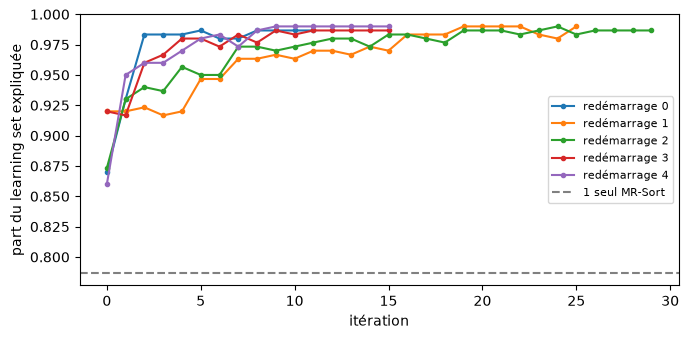

In [5]:
fig, ax = plt.subplots(figsize=(7, 3.5))
for r, h in enumerate(two['history']):
    ax.plot(np.array(h) / len(y), marker='o', ms=3, label=f'redémarrage {r}')
ax.axhline(np.mean(classify(X, single) == y), color='grey', ls='--', label='1 seul MR-Sort')
ax.set_xlabel('itération'); ax.set_ylabel('part du learning set expliquée'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

In [6]:
for k, m in enumerate(two['models']):
    print(f'Segment {k+1} ({np.sum(two["seg"] == k)} objets) : lambda = {m["lam"]:.3f}')
    display(describe(m))

Segment 1 (121 objets) : lambda = 0.500


,c1,c2,c3,c4,c5,c6
b^1,0.144,0.198,0.562,0.431,0.246,0.163
b^2,0.522,0.812,0.982,0.495,0.301,0.332
w,0.250,0.000,0.250,0.250,0.000,0.250


Segment 2 (179 objets) : lambda = 0.500


,c1,c2,c3,c4,c5,c6
b^1,0.124,0.074,0.249,0.000,0.000,0.205
b^2,0.467,0.311,0.624,0.226,0.315,0.974
w,0.250,0.250,0.250,0.000,0.250,0.000


## Validation sur données synthétiques (segments connus)
`run_synthetic.py` : 2 modèles ground truth, 300 objets, 6 critères, 3 classes ; 5 instances par configuration. *fid* = proportion de 5000 objets de test classés pareil par le modèle appris et le vrai modèle (qualité du jalon 1). *plafond* = modèles appris par lincs sur la **vraie** partition. *segments_retrouves* est mesuré sur les objets où les deux vrais modèles divergent (pour les autres, le segment n'est pas identifiable).

In [7]:
syn = pd.read_csv('results/synthetic.csv')
syn.groupby(['share', 'noise']).mean(numeric_only=True).drop(columns='instance').round(3).T

share                    0.50              0.75         
noise                     0.0      0.1      0.0      0.1
accord_vrais_modeles    0.480    0.489    0.480    0.489
train_1_modele          0.795    0.725    0.868    0.783
train_2_modeles         0.997    0.951    0.994    0.955
segments_retrouves      0.869    0.621    0.824    0.806
fid_M1_heuristique      0.770    0.526    0.782    0.816
fid_M2_heuristique      0.849    0.681    0.738    0.660
fid_M1_1_modele         0.694    0.671    0.905    0.823
fid_M2_1_modele         0.703    0.690    0.502    0.541
fid_M1_plafond          0.927    0.869    0.952    0.882
fid_M2_plafond          0.953    0.913    0.922    0.841
temps_s               157.906  182.921  123.294  152.721

## Résultats sur les datasets supermarket (6 critères, 3 catégories)
Découpage 80/20. *test_2_modeles* = proportion d'objets de test bien classés par le modèle de leur segment (segment le plus favorable, puisque le segment d'un nouvel objet n'est pas observé). Pour vérifier que le gain ne vient pas seulement du fait d'avoir « deux chances », on compare au *témoin* : 2 modèles appris sur une partition aléatoire.

In [8]:
sup = pd.read_csv('results/supermarket_cr06_ca03.csv')
cols = ['train_1_modele', 'test_1_modele', 'train_2_modeles', 'test_2_modeles', 'train_temoin', 'test_temoin']
sup.groupby(['type', 'rep', 'bruit'])[cols].mean().round(3)

train_1_modele  test_1_modele  train_2_modeles  \
type   rep   bruit                                                   
type_a 50-50 0               0.763          0.696            0.989   
             10              0.692          0.586            0.927   
       75-25 0               0.845          0.818            0.985   
             10              0.727          0.707            0.936   
type_b 50-50 0               0.664          0.543            0.995   
             10              0.626          0.492            0.938   
       75-25 0               0.810          0.819            0.996   
             10              0.736          0.683            0.953   

                    test_2_modeles  train_temoin  test_temoin  
type   rep   bruit                                             
type_a 50-50 0               0.926         0.877        0.826  
             10              0.861         0.812        0.729  
       75-25 0               0.958         0.896        0.893  
             10              0.856         0.834        0.792  
type_b 50-50 0               0.968         0.827        0.754  
             10              0.924         0.763        0.686  
       75-25 0               0.962         0.838        0.833  
             10              0.878         0.767        0.706

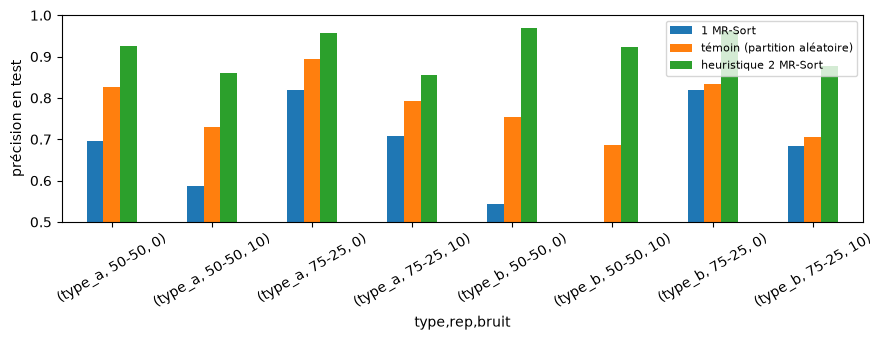

In [9]:
g = sup.groupby(['type', 'rep', 'bruit'])[['test_1_modele', 'test_temoin', 'test_2_modeles']].mean()
ax = g.plot.bar(figsize=(9, 3.5), ylim=(0.5, 1.0), rot=30)
ax.set_ylabel('précision en test'); ax.legend(['1 MR-Sort', 'témoin (partition aléatoire)', 'heuristique 2 MR-Sort'], fontsize=8)
plt.tight_layout(); plt.show()